# Aula 02 — Introdução ao ML e KDD · Exercícios

**Unidade 1 — Introdução à Ciência de Dados e Python** · ver também: [conteúdo](conteudo.ipynb) · [atividades](atividades.ipynb)

## 💻 Exemplo Prático — Pré-processamento de Dados (Aula 02)

Pré-Processamento de dados, em Python puro, para diminuir dados inconsistentesno dataset do ENEM 2025. Reaproveita o microdado `RESULTADOS_2025_RN.csv` já disponível na Aula 01.

---
## Notebooks KDD Passos de 1 a 3

> Pacote `notebooks_KDD.zip` extraído nesta pasta: `aula2_passo1_selecao.ipynb`, `aula2_passo2_preprocessamento.ipynb`, `aula2_passo3_transformacao.ipynb`.

## Notebooks KDD Passos de 1 a 3 — `aula2_passo1_selecao.ipynb`

> Notebook original do professor (cópia intacta ao lado deste arquivo). Rode em ordem; os caminhos `dados/...` são relativos à pasta da aula.

In [ ]:
import pandas as pd

# ── Caminhos dos arquivos ───────────────────────────────────────────────────
RESULTADOS = "RESULTADOS_2025_RN.csv"
CATALOGO   = "catalogo_escolas_rn.csv"

# ── 1.1  Carregamento dos dados brutos ─────────────────────────────────────
print("=" * 70)
print("PASSO 1 — SELEÇÃO")
print("=" * 70)

PASSO 1 — SELEÇÃO


In [ ]:
df_raw = pd.read_csv(RESULTADOS, sep=";", encoding="latin1")
df_cat = pd.read_csv(CATALOGO,   sep=",", encoding="latin1")

In [ ]:
print(f"\n[RAW] Registros totais no arquivo de resultados   : {len(df_raw):,}")
print(f"[RAW] Colunas disponíveis                         : {df_raw.shape[1]}")
print(f"[CAT] Escolas no catálogo                         : {len(df_cat):,}")


[RAW] Registros totais no arquivo de resultados   : 30,449
[RAW] Colunas disponíveis                         : 70
[CAT] Escolas no catálogo                         : 4,938


In [ ]:
presenca_completa = (
    (df_raw["TP_PRESENCA_CN"] == 1) &
    (df_raw["TP_PRESENCA_CH"] == 1) &
    (df_raw["TP_PRESENCA_LC"] == 1) &
    (df_raw["TP_PRESENCA_MT"] == 1)
)

presenca_completa

,0
0,True
1,False
2,True
3,True
4,True
...,...
30444,True
30445,True
30446,True
30447,True


In [ ]:
df_presentes = df_raw[presenca_completa].copy()

print(f"\n [SELEÇÃO] Candidatos com presença completa       : {len(df_presentes):,}")
print(f"[EXCLUSÃO] Descartados por ausência               : {len(df_raw) - len(df_presentes):,}")



 [SELEÇÃO] Candidatos com presença completa       : 25,923
[EXCLUSÃO] Descartados por ausência               : 4,526


In [ ]:
COLUNAS = [
    "CO_ESCOLA",               # chave para join com catálogo
    "NO_MUNICIPIO_ESC",        # município da escola
    "TP_DEPENDENCIA_ADM_ESC",  # 1=Federal, 2=Estadual, 3=Municipal, 4=Privada
    "TP_LOCALIZACAO_ESC",      # 1=Urbana, 2=Rural
    "NU_NOTA_CN",              # Ciências da Natureza
    "NU_NOTA_CH",              # Ciências Humanas
    "NU_NOTA_LC",              # Linguagens e Códigos
    "NU_NOTA_MT",              # Matemática
    "NU_NOTA_REDACAO",      # Redação
]

df_sel = df_presentes[COLUNAS].copy()

In [ ]:
df_sel = df_sel.merge(df_cat, on="CO_ESCOLA", how="left")

print(f"\n[SELEÇÃO] Colunas selecionadas                   : {df_sel.shape[1]}")
print(f"[SELEÇÃO] Escolas identificadas pelo catálogo    : "
      f"{df_sel['NO_ESCOLA'].notna().sum():,} / {len(df_sel):,}")


[SELEÇÃO] Colunas selecionadas                   : 10
[SELEÇÃO] Escolas identificadas pelo catálogo    : 25,738 / 25,923


In [ ]:
df_sel

,CO_ESCOLA,NO_MUNICIPIO_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO,NO_ESCOLA
0,24077879,Extremoz,2,2,477.8,392.1,476.0,442.8,400.0,CENTRO DE EDUCACAO PROFISSIONAL E AMBIENTAL ES...
1,24070297,São Miguel,2,1,455.2,517.2,510.7,370.9,520.0,ESCOLA ESTADUAL GILNEY DE SOUZA
2,24005908,Caraúbas,2,1,395.9,468.0,443.0,491.9,0.0,ESCOLA ESTADUAL SEBASTIAO GURGEL
3,24000647,Baraúna,2,1,498.0,393.3,502.1,356.7,800.0,ESCOLA ESTADUAL JOAO DE ABREU
4,24083054,São Gonçalo do Amarante,1,1,338.7,492.0,484.0,437.1,520.0,IFRN - CAMPUS SAO GONCALO DO AMARANTE
...,...,...,...,...,...,...,...,...,...,...
25918,24039357,Barcelona,2,1,430.7,332.8,512.8,504.0,540.0,ESCOLA ESTADUAL PROFESSOR TERTULIANO PINHEIRO ...
25919,24082147,Goianinha,4,1,563.9,432.0,547.9,601.8,520.0,COLEGIO NOSSA SENHORA DOS PRAZERES LTDA
25920,24061778,Goianinha,2,1,433.7,564.5,502.5,539.1,600.0,ESCOLA ESTADUAL JOAO TIBURCIO
25921,24060798,Arês,2,1,400.4,432.8,400.4,412.6,280.0,ESCOLA ESTADUAL JACUMAUMA


In [ ]:


print("\n[SELEÇÃO] Candidatos por tipo de escola:")
print(df_sel["TIPO_ESCOLA"].value_counts().to_string())


[SELEÇÃO] Candidatos por tipo de escola:


KeyError: 'TIPO_ESCOLA'

In [ ]:
df_sel

In [ ]:
df_sel.to_csv("dados_selecionados.csv", index=False, encoding="utf-8")
print(f"\n[OK] Arquivo salvo: dados_selecionados.csv  ({len(df_sel):,} registros, "
      f"{df_sel.shape[1]} colunas)")
print("\nPronto! Execute o passo2_preprocessamento.py em seguida.")

## Notebooks KDD Passos de 1 a 3 — `aula2_passo2_preprocessamento.ipynb`

> Notebook original do professor (cópia intacta ao lado deste arquivo). Rode em ordem; os caminhos `dados/...` são relativos à pasta da aula.

In [454]:

%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [455]:
# ── Entrada ─────────────────────────────────────────────────────────────────
df = pd.read_csv("dados_selecionados.csv", encoding="utf-8")

print("=" * 65)
print("PASSO 2 — PRÉ-PROCESSAMENTO")
print("=" * 65)
print(f"\n[ENTRADA] {len(df):,} registros, {df.shape[1]} colunas")


PASSO 2 — PRÉ-PROCESSAMENTO

[ENTRADA] 25,923 registros, 11 colunas


In [456]:
NOTAS = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]

print("\n[DIAGNÓSTICO] Valores ausentes (NaN) por coluna:")
for col in NOTAS:
    n = df[col].isna().sum()
    print(f"   {col} : {n} ({n/len(df)*100:.1f}%)")

print("\n[DIAGNÓSTICO] Notas zero (suspeitas) por coluna:")
for col in NOTAS:
    n = (df[col] == 0).sum()
    print(f"   {col}: {n} ({n/len(df)*100:.1f}%)")


[DIAGNÓSTICO] Valores ausentes (NaN) por coluna:
   NU_NOTA_CN : 0 (0.0%)
   NU_NOTA_CH : 0 (0.0%)
   NU_NOTA_LC : 0 (0.0%)
   NU_NOTA_MT : 0 (0.0%)
   NU_NOTA_REDACAO : 0 (0.0%)

[DIAGNÓSTICO] Notas zero (suspeitas) por coluna:
   NU_NOTA_CN: 1 (0.0%)
   NU_NOTA_CH: 39 (0.2%)
   NU_NOTA_LC: 3 (0.0%)
   NU_NOTA_MT: 2 (0.0%)
   NU_NOTA_REDACAO: 1555 (6.0%)


In [457]:
antes = len(df)
for col in NOTAS:
    df[col] = df[col].replace(0, np.nan)

In [458]:
print(f"\n[TRATAMENTO] Notas zero convertidas para NaN em: {NOTAS}")



[TRATAMENTO] Notas zero convertidas para NaN em: ['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO']


In [459]:
df_clean = df.dropna(subset=NOTAS).copy()
removidos = antes - len(df_clean)
print(f"[TRATAMENTO] Registros removidos por nota NaN    : {removidos:,}")
print(f"[RESULTADO]  Registros restantes                 : {len(df_clean):,}")

[TRATAMENTO] Registros removidos por nota NaN    : 1,593
[RESULTADO]  Registros restantes                 : 24,330


In [460]:
dupl = df_clean.duplicated().sum()
print(f"\n[DIAGNÓSTICO] Registros duplicados               : {dupl}")
if dupl:
    df_clean = df_clean.drop_duplicates()
    print(f"[TRATAMENTO]  Duplicatas removidas.")


[DIAGNÓSTICO] Registros duplicados               : 0


In [461]:
# ── 2.5  Checar e corrigir tipos de dados ───────────────────────────────────
df_clean["CO_ESCOLA"] = df_clean["CO_ESCOLA"].astype(str)
df_clean["TP_LOCALIZACAO_ESC"] = df_clean["TP_LOCALIZACAO_ESC"].astype("Int64")
df_clean["TP_DEPENDENCIA_ADM_ESC"] = df_clean["TP_DEPENDENCIA_ADM_ESC"].astype("Int64")


In [462]:
df_clean

,CO_ESCOLA,NO_MUNICIPIO_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO,NO_ESCOLA,TIPO_ESCOLA
0,24077879,Extremoz,2,2,477.8,392.1,476.0,442.8,400.0,CENTRO DE EDUCACAO PROFISSIONAL E AMBIENTAL ES...,Estadual
1,24070297,São Miguel,2,1,455.2,517.2,510.7,370.9,520.0,ESCOLA ESTADUAL GILNEY DE SOUZA,Estadual
3,24000647,Baraúna,2,1,498.0,393.3,502.1,356.7,800.0,ESCOLA ESTADUAL JOAO DE ABREU,Estadual
4,24083054,São Gonçalo do Amarante,1,1,338.7,492.0,484.0,437.1,520.0,IFRN - CAMPUS SAO GONCALO DO AMARANTE,Federal
5,24087351,Extremoz,2,1,414.5,470.5,506.9,385.6,440.0,CEEP CENTRO DE EDUCACAO PROFISSIONAL PROFESSOR...,Estadual
...,...,...,...,...,...,...,...,...,...,...,...
25918,24039357,Barcelona,2,1,430.7,332.8,512.8,504.0,540.0,ESCOLA ESTADUAL PROFESSOR TERTULIANO PINHEIRO ...,Estadual
25919,24082147,Goianinha,4,1,563.9,432.0,547.9,601.8,520.0,COLEGIO NOSSA SENHORA DOS PRAZERES LTDA,Privada
25920,24061778,Goianinha,2,1,433.7,564.5,502.5,539.1,600.0,ESCOLA ESTADUAL JOAO TIBURCIO,Estadual
25921,24060798,Arês,2,1,400.4,432.8,400.4,412.6,280.0,ESCOLA ESTADUAL JACUMAUMA,Estadual


In [463]:
# ── 2.6  Padronizar tipo de escola faltante (sem match no catálogo) ──────────
sem_nome = df_clean["NO_ESCOLA"].isna().sum()
if sem_nome:
    df_clean["NO_ESCOLA"] = df_clean["NO_ESCOLA"].fillna("Escola não identificada")
    print(f"\n[TRATAMENTO] Escolas sem match no catálogo       : {sem_nome} → preenchidas")


[TRATAMENTO] Escolas sem match no catálogo       : 175 → preenchidas


Text(0.5, 0.98, 'Distribuição das Notas após Pré-processamento\n(candidatos com presença completa e notas válidas)')

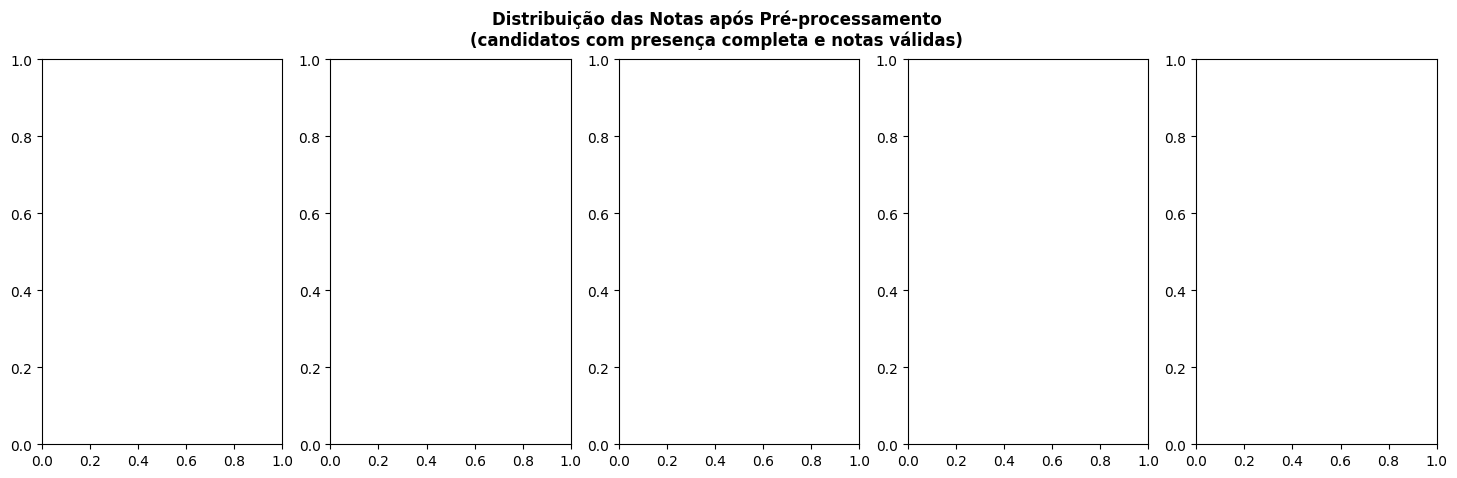

In [464]:
# ── 2.7  Boxplots antes/depois da limpeza para cada nota ────────────────────
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
fig.suptitle("Distribuição das Notas após Pré-processamento\n(candidatos com presença completa e notas válidas)",
             fontsize=12, fontweight="bold")


In [465]:
LABELS = ["Ciências\nNatureza", "Ciências\nHumanas", "Linguagens", "Matemática", "Redação"]
CORES  = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759", "#76b7b2"]

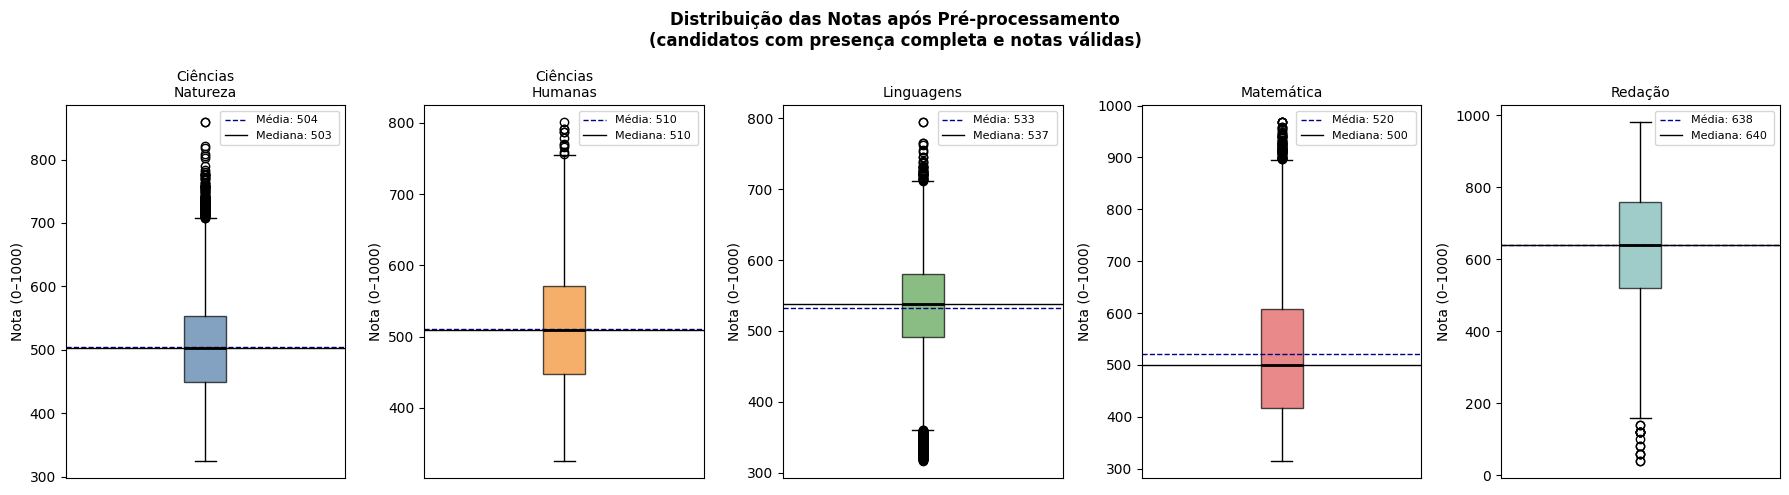


[OK] Gráfico salvo: passo2_boxplots.png


<Figure size 640x480 with 0 Axes>

In [466]:
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
fig.suptitle("Distribuição das Notas após Pré-processamento\n(candidatos com presença completa e notas válidas)",
             fontsize=12, fontweight="bold")

# Assuming NOTAS, LABELS, CORES, df_clean are still defined from previous cells
for ax, col, label, cor in zip(axes, NOTAS, LABELS, CORES):
    ax.boxplot(df_clean[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor=cor, alpha=0.7),
               medianprops=dict(color="black", linewidth=2))
    ax.set_title(label, fontsize=10)
    ax.set_ylabel("Nota (0–1000)")
    ax.set_xticks([])
    media = df_clean[col].mean()
    mediana = df_clean[col].median()
    ax.axhline(media, color="navy", linestyle="--", linewidth=1,
               label=f"Média: {media:.0f} ")
    ax.axhline(mediana, color="black", linestyle="-", linewidth=1,
               label=f"Mediana: {mediana:.0f} ")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

plt.savefig("passo2_boxplots.png", dpi=120, bbox_inches="tight")
print("\n[OK] Gráfico salvo: passo2_boxplots.png")

In [473]:
# ── 2.8  Relatório final ─────────────────────────────────────────────────────
print("\n[RESUMO PRÉ-PROCESSAMENTO]")
print(f"   Registros de entrada  : {antes:,}")
print(f"   Registros de saída    : {len(df_clean):,}")
print(f"   Perda total           : {antes - len(df_clean):,} ({(antes-len(df_clean))/antes*100:.1f}%)")
print("\n[ESTATÍSTICAS FINAIS DAS NOTAS]")
print(df_clean[NOTAS].describe().round(2).to_string())


[RESUMO PRÉ-PROCESSAMENTO]
   Registros de entrada  : 25,923
   Registros de saída    : 24,330
   Perda total           : 1,593 (6.1%)

[ESTATÍSTICAS FINAIS DAS NOTAS]
       NU_NOTA_CN  NU_NOTA_CH  NU_NOTA_LC  NU_NOTA_MT  NU_NOTA_REDACAO
count    24330.00    24330.00    24330.00    24330.00         24330.00
mean       503.88      510.46      532.86      520.11           638.38
std         75.35       81.77       68.25      126.67           160.20
min        324.70      325.60      316.50      314.80            40.00
25%        449.80      447.20      491.70      416.80           520.00
50%        502.60      509.85      537.40      499.80           640.00
75%        553.00      570.40      579.70      608.40           760.00
max        858.70      800.80      794.50      967.70           980.00


In [468]:
df_clean.to_csv("dados_preprocessados.csv", index=False, encoding="utf-8")
print(f"\n[OK] Arquivo salvo: dados_preprocessados.csv  ({len(df_clean):,} registros)")
print("\nPronto! Execute o passo3_transformacao.py em seguida.")


[OK] Arquivo salvo: dados_preprocessados.csv  (24,330 registros)

Pronto! Execute o passo3_transformacao.py em seguida.


## Notebooks KDD Passos de 1 a 3 — `aula2_passo3_transformacao.ipynb`

> Notebook original do professor (cópia intacta ao lado deste arquivo). Rode em ordem; os caminhos `dados/...` são relativos à pasta da aula.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

In [2]:
df = pd.read_csv("dados_preprocessados.csv", encoding="utf-8")

print("=" * 65)
print("PASSO 3 — TRANSFORMAÇÃO")
print("=" * 65)
print(f"\n[ENTRADA] {len(df):,} registros")

NOTAS_OBJ  = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT"]
NOTAS_TODAS= NOTAS_OBJ + ["NU_NOTA_REDACAO"]

PASSO 3 — TRANSFORMAÇÃO

[ENTRADA] 24,330 registros


In [3]:
# ── 3.1  Atributos derivados numéricos ──────────────────────────────────────
df["MEDIA_OBJETIVAS"] = df[NOTAS_OBJ].mean(axis=1).round(2)

# Média ponderada: 4 provas objetivas + redação (peso 1)
df["MEDIA_GERAL"] = (
    (df[NOTAS_OBJ].sum(axis=1) + df["NU_NOTA_REDACAO"]) / 5
).round(2)

df["DESVIO_NOTAS"] = df[NOTAS_TODAS].std(axis=1).round(2)

print("\n[FEATURE] MEDIA_OBJETIVAS, MEDIA_GERAL, DESVIO_NOTAS criados")


[FEATURE] MEDIA_OBJETIVAS, MEDIA_GERAL, DESVIO_NOTAS criados


In [4]:
df

,CO_ESCOLA,NO_MUNICIPIO_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO,NO_ESCOLA,TIPO_ESCOLA,MEDIA_OBJETIVAS,MEDIA_GERAL,DESVIO_NOTAS
0,24077879,Extremoz,2,2,477.8,392.1,476.0,442.8,400.0,CENTRO DE EDUCACAO PROFISSIONAL E AMBIENTAL ES...,Estadual,447.18,437.74,40.62
1,24070297,São Miguel,2,1,455.2,517.2,510.7,370.9,520.0,ESCOLA ESTADUAL GILNEY DE SOUZA,Estadual,463.50,474.80,63.85
2,24000647,Baraúna,2,1,498.0,393.3,502.1,356.7,800.0,ESCOLA ESTADUAL JOAO DE ABREU,Estadual,437.52,510.02,174.23
3,24083054,São Gonçalo do Amarante,1,1,338.7,492.0,484.0,437.1,520.0,IFRN - CAMPUS SAO GONCALO DO AMARANTE,Federal,437.95,454.36,71.20
4,24087351,Extremoz,2,1,414.5,470.5,506.9,385.6,440.0,CEEP CENTRO DE EDUCACAO PROFISSIONAL PROFESSOR...,Estadual,444.38,443.50,47.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24325,24039357,Barcelona,2,1,430.7,332.8,512.8,504.0,540.0,ESCOLA ESTADUAL PROFESSOR TERTULIANO PINHEIRO ...,Estadual,445.08,464.06,83.79
24326,24082147,Goianinha,4,1,563.9,432.0,547.9,601.8,520.0,COLEGIO NOSSA SENHORA DOS PRAZERES LTDA,Privada,536.40,533.12,63.80
24327,24061778,Goianinha,2,1,433.7,564.5,502.5,539.1,600.0,ESCOLA ESTADUAL JOAO TIBURCIO,Estadual,509.95,527.96,63.60
24328,24060798,Arês,2,1,400.4,432.8,400.4,412.6,280.0,ESCOLA ESTADUAL JACUMAUMA,Estadual,411.55,385.24,60.30


In [8]:
# ── 3.2  Atributos derivados categóricos ────────────────────────────────────
MAPA_AREA = {
    "NU_NOTA_CN": "Ciências Natureza",
    "NU_NOTA_CH": "Ciências Humanas",
    "NU_NOTA_LC": "Linguagens",
    "NU_NOTA_MT": "Matemática",
    "NU_NOTA_REDACAO": "Redação",
}

df["MELHOR_AREA"] = df[NOTAS_TODAS].idxmax(axis=1).map(MAPA_AREA)
df["PIOR_AREA"]   = df[NOTAS_TODAS].idxmin(axis=1).map(MAPA_AREA)

print("[FEATURE] MELHOR_AREA e PIOR_AREA criados")
print("\n  Melhor área mais comum:")
print(df["MELHOR_AREA"].value_counts().to_string())
print("\n  Pior área mais comum:")
print(df["PIOR_AREA"].value_counts().to_string())


[FEATURE] MELHOR_AREA e PIOR_AREA criados

  Melhor área mais comum:
MELHOR_AREA
Redação              16852
Matemática            2597
Linguagens            2491
Ciências Humanas      1206
Ciências Natureza     1184

  Pior área mais comum:
PIOR_AREA
Matemática           7465
Ciências Natureza    7189
Ciências Humanas     5107
Linguagens           2497
Redação              2072


In [9]:
df

,CO_ESCOLA,NO_MUNICIPIO_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO,NO_ESCOLA,TIPO_ESCOLA,MEDIA_OBJETIVAS,MEDIA_GERAL,DESVIO_NOTAS,MELHOR_AREA,PIOR_AREA
0,24077879,Extremoz,2,2,477.8,392.1,476.0,442.8,400.0,CENTRO DE EDUCACAO PROFISSIONAL E AMBIENTAL ES...,Estadual,447.18,437.74,40.62,Ciências Natureza,Ciências Humanas
1,24070297,São Miguel,2,1,455.2,517.2,510.7,370.9,520.0,ESCOLA ESTADUAL GILNEY DE SOUZA,Estadual,463.50,474.80,63.85,Redação,Matemática
2,24000647,Baraúna,2,1,498.0,393.3,502.1,356.7,800.0,ESCOLA ESTADUAL JOAO DE ABREU,Estadual,437.52,510.02,174.23,Redação,Matemática
3,24083054,São Gonçalo do Amarante,1,1,338.7,492.0,484.0,437.1,520.0,IFRN - CAMPUS SAO GONCALO DO AMARANTE,Federal,437.95,454.36,71.20,Redação,Ciências Natureza
4,24087351,Extremoz,2,1,414.5,470.5,506.9,385.6,440.0,CEEP CENTRO DE EDUCACAO PROFISSIONAL PROFESSOR...,Estadual,444.38,443.50,47.31,Linguagens,Matemática
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24325,24039357,Barcelona,2,1,430.7,332.8,512.8,504.0,540.0,ESCOLA ESTADUAL PROFESSOR TERTULIANO PINHEIRO ...,Estadual,445.08,464.06,83.79,Redação,Ciências Humanas
24326,24082147,Goianinha,4,1,563.9,432.0,547.9,601.8,520.0,COLEGIO NOSSA SENHORA DOS PRAZERES LTDA,Privada,536.40,533.12,63.80,Matemática,Ciências Humanas
24327,24061778,Goianinha,2,1,433.7,564.5,502.5,539.1,600.0,ESCOLA ESTADUAL JOAO TIBURCIO,Estadual,509.95,527.96,63.60,Redação,Ciências Natureza
24328,24060798,Arês,2,1,400.4,432.8,400.4,412.6,280.0,ESCOLA ESTADUAL JACUMAUMA,Estadual,411.55,385.24,60.30,Ciências Humanas,Redação


In [10]:
# ── 3.3  Codificação de variáveis categóricas ───────────────────────────────
# Localização: binária (simples e interpretável)
df["LOCALIZACAO_RURAL"] = (df["TP_LOCALIZACAO_ESC"] == 2).astype(int)

# Tipo de escola: One-Hot Encoding (para evitar ordenação implícita)
df["TIPO_ESCOLA"] = df["TIPO_ESCOLA"].fillna("Estadual")
dummies = pd.get_dummies(df["TIPO_ESCOLA"], prefix="ESCOLA", drop_first=False)
df = pd.concat([df, dummies], axis=1)

# Melhor área: Label Encoding (para algoritmos tree-based)
le = LabelEncoder()
df["MELHOR_AREA_COD"] = le.fit_transform(df["MELHOR_AREA"])
df["PIOR_AREA_COD"]   = le.fit_transform(df["PIOR_AREA"])

print("\n[ENCODING] LOCALIZACAO_RURAL, One-Hot TIPO_ESCOLA, Label MELHOR/PIOR_AREA")



[ENCODING] LOCALIZACAO_RURAL, One-Hot TIPO_ESCOLA, Label MELHOR/PIOR_AREA


In [11]:
df

,CO_ESCOLA,NO_MUNICIPIO_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO,NO_ESCOLA,...,MEDIA_GERAL,DESVIO_NOTAS,MELHOR_AREA,PIOR_AREA,LOCALIZACAO_RURAL,ESCOLA_Estadual,ESCOLA_Federal,ESCOLA_Privada,MELHOR_AREA_COD,PIOR_AREA_COD
0,24077879,Extremoz,2,2,477.8,392.1,476.0,442.8,400.0,CENTRO DE EDUCACAO PROFISSIONAL E AMBIENTAL ES...,...,437.74,40.62,Ciências Natureza,Ciências Humanas,1,True,False,False,1,0
1,24070297,São Miguel,2,1,455.2,517.2,510.7,370.9,520.0,ESCOLA ESTADUAL GILNEY DE SOUZA,...,474.80,63.85,Redação,Matemática,0,True,False,False,4,3
2,24000647,Baraúna,2,1,498.0,393.3,502.1,356.7,800.0,ESCOLA ESTADUAL JOAO DE ABREU,...,510.02,174.23,Redação,Matemática,0,True,False,False,4,3
3,24083054,São Gonçalo do Amarante,1,1,338.7,492.0,484.0,437.1,520.0,IFRN - CAMPUS SAO GONCALO DO AMARANTE,...,454.36,71.20,Redação,Ciências Natureza,0,False,True,False,4,1
4,24087351,Extremoz,2,1,414.5,470.5,506.9,385.6,440.0,CEEP CENTRO DE EDUCACAO PROFISSIONAL PROFESSOR...,...,443.50,47.31,Linguagens,Matemática,0,True,False,False,2,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24325,24039357,Barcelona,2,1,430.7,332.8,512.8,504.0,540.0,ESCOLA ESTADUAL PROFESSOR TERTULIANO PINHEIRO ...,...,464.06,83.79,Redação,Ciências Humanas,0,True,False,False,4,0
24326,24082147,Goianinha,4,1,563.9,432.0,547.9,601.8,520.0,COLEGIO NOSSA SENHORA DOS PRAZERES LTDA,...,533.12,63.80,Matemática,Ciências Humanas,0,False,False,True,3,0
24327,24061778,Goianinha,2,1,433.7,564.5,502.5,539.1,600.0,ESCOLA ESTADUAL JOAO TIBURCIO,...,527.96,63.60,Redação,Ciências Natureza,0,True,False,False,4,1
24328,24060798,Arês,2,1,400.4,432.8,400.4,412.6,280.0,ESCOLA ESTADUAL JACUMAUMA,...,385.24,60.30,Ciências Humanas,Redação,0,True,False,False,0,4


In [12]:
# ── 3.4  Variável-alvo: NIVEL_DESEMPENHO ────────────────────────────────────
LIMITES = [0, 400, 550, 700, 1001]
ROTULOS = ["Insuficiente", "Regular", "Bom", "Excelente"]

df["NIVEL_DESEMPENHO"] = pd.cut(
    df["MEDIA_GERAL"],
    bins=LIMITES,
    labels=ROTULOS,
    right=False
)

print("\n[TARGET] Distribuição de NIVEL_DESEMPENHO:")
contagem = df["NIVEL_DESEMPENHO"].value_counts().sort_index()
for nivel, n in contagem.items():
    print(f"   {nivel:<14}: {n:>5} ({n/len(df)*100:.1f}%)")


[TARGET] Distribuição de NIVEL_DESEMPENHO:
   Insuficiente  :   686 (2.8%)
   Regular       : 13218 (54.3%)
   Bom           :  9376 (38.5%)
   Excelente     :  1050 (4.3%)


In [13]:
# ── 3.5  Normalização Min-Max das notas brutas ──────────────────────────────
# (útil para algoritmos sensíveis à escala: KNN, SVM, Redes Neurais)
scaler = MinMaxScaler()
COLUNAS_NORM = NOTAS_TODAS + ["MEDIA_OBJETIVAS", "MEDIA_GERAL", "DESVIO_NOTAS"]
df_norm = df.copy()
df_norm[[c + "_NORM" for c in COLUNAS_NORM]] = scaler.fit_transform(df[COLUNAS_NORM])

print("\n[NORMALIZAÇÃO] Min-Max aplicada às notas e médias")
print(f"   Faixa original  MEDIA_GERAL: {df['MEDIA_GERAL'].min():.1f} – {df['MEDIA_GERAL'].max():.1f}")
print(f"   Faixa normalizd MEDIA_GERAL: "
      f"{df_norm['MEDIA_GERAL_NORM'].min():.3f} – {df_norm['MEDIA_GERAL_NORM'].max():.3f}")



[NORMALIZAÇÃO] Min-Max aplicada às notas e médias
   Faixa original  MEDIA_GERAL: 306.8 – 843.5
   Faixa normalizd MEDIA_GERAL: 0.000 – 1.000


In [14]:
df_norm

,CO_ESCOLA,NO_MUNICIPIO_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO,NO_ESCOLA,...,PIOR_AREA_COD,NIVEL_DESEMPENHO,NU_NOTA_CN_NORM,NU_NOTA_CH_NORM,NU_NOTA_LC_NORM,NU_NOTA_MT_NORM,NU_NOTA_REDACAO_NORM,MEDIA_OBJETIVAS_NORM,MEDIA_GERAL_NORM,DESVIO_NOTAS_NORM
0,24077879,Extremoz,2,2,477.8,392.1,476.0,442.8,400.0,CENTRO DE EDUCACAO PROFISSIONAL E AMBIENTAL ES...,...,0,Regular,0.286704,0.139941,0.333682,0.196048,0.382979,0.196599,0.243962,0.144672
1,24070297,São Miguel,2,1,455.2,517.2,510.7,370.9,520.0,ESCOLA ESTADUAL GILNEY DE SOUZA,...,3,Regular,0.244382,0.403199,0.406276,0.085924,0.510638,0.230035,0.313022,0.247510
2,24000647,Baraúna,2,1,498.0,393.3,502.1,356.7,800.0,ESCOLA ESTADUAL JOAO DE ABREU,...,3,Regular,0.324532,0.142466,0.388285,0.064175,0.808511,0.176808,0.378652,0.736155
3,24083054,São Gonçalo do Amarante,1,1,338.7,492.0,484.0,437.1,520.0,IFRN - CAMPUS SAO GONCALO DO AMARANTE,...,1,Regular,0.026217,0.350168,0.350418,0.187318,0.510638,0.177689,0.274933,0.280048
4,24087351,Extremoz,2,1,414.5,470.5,506.9,385.6,440.0,CEEP CENTRO DE EDUCACAO PROFISSIONAL PROFESSOR...,...,3,Regular,0.168165,0.304924,0.398326,0.108439,0.425532,0.190863,0.254696,0.174288
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24325,24039357,Barcelona,2,1,430.7,332.8,512.8,504.0,540.0,ESCOLA ESTADUAL PROFESSOR TERTULIANO PINHEIRO ...,...,0,Regular,0.198502,0.015152,0.410669,0.289784,0.531915,0.192297,0.293008,0.335783
24326,24082147,Goianinha,4,1,563.9,432.0,547.9,601.8,520.0,COLEGIO NOSSA SENHORA DOS PRAZERES LTDA,...,0,Regular,0.447940,0.223906,0.484100,0.439577,0.510638,0.379389,0.421698,0.247289
24327,24061778,Goianinha,2,1,433.7,564.5,502.5,539.1,600.0,ESCOLA ESTADUAL JOAO TIBURCIO,...,1,Regular,0.204120,0.502736,0.389121,0.343544,0.595745,0.325200,0.412083,0.246403
24328,24060798,Arês,2,1,400.4,432.8,400.4,412.6,280.0,ESCOLA ESTADUAL JACUMAUMA,...,4,Insuficiente,0.141760,0.225589,0.175523,0.149793,0.255319,0.123602,0.146131,0.231794


In [15]:
# ── 3.6  Visualização da distribuição de média geral ────────────────────────
CORES_NIVEL = {
    "Insuficiente": "#e15759",
    "Regular"     : "#f28e2b",
    "Bom"         : "#4e79a7",
    "Excelente"   : "#59a14f",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Passo 3 — Transformação: Variável-Alvo e Distribuição", fontsize=13, fontweight="bold")

# Histograma da média geral com fronteiras dos níveis
ax = axes[0]
ax.hist(df["MEDIA_GERAL"], bins=60, color="#4e79a7", edgecolor="white", alpha=0.8)
for lim, rot in zip(LIMITES[1:-1], ROTULOS[:-1]):
    ax.axvline(lim, color="red", linestyle="--", linewidth=1.2)
    ax.text(lim + 5, ax.get_ylim()[1] * 0.95, rot, fontsize=8, color="red", rotation=90, va="top")
ax.set_title("Histograma da Média Geral")
ax.set_xlabel("Média Geral (pontos)")
ax.set_ylabel("Frequência")

# Pizza dos níveis
ax = axes[1]
sizes  = [contagem.get(r, 0) for r in ROTULOS]
colors = [CORES_NIVEL[r] for r in ROTULOS]
wedges, texts, autotexts = ax.pie(
    sizes, labels=ROTULOS, colors=colors,
    autopct="%1.1f%%", startangle=140, pctdistance=0.75
)
for at in autotexts:
    at.set_fontsize(9)
ax.set_title("Distribuição de Nível de Desempenho")

plt.tight_layout()
plt.savefig("passo3_transformacao.png", dpi=120, bbox_inches="tight")
plt.close()
print("\n[OK] Gráfico salvo: passo3_transformacao.png")


[OK] Gráfico salvo: passo3_transformacao.png


In [16]:
# ── 3.7  Definir conjunto de features para ML ───────────────────────────────
FEATURES = (
    ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO",
     "MEDIA_OBJETIVAS", "DESVIO_NOTAS", "LOCALIZACAO_RURAL",
     "MELHOR_AREA_COD", "PIOR_AREA_COD"]
    + [c for c in df.columns if c.startswith("ESCOLA_")]
)
TARGET = "NIVEL_DESEMPENHO"

print(f"\n[FEATURES FINAIS] ({len(FEATURES)} atributos):")
for f in FEATURES:
    print(f"   • {f}")



[FEATURES FINAIS] (13 atributos):
   • NU_NOTA_CN
   • NU_NOTA_CH
   • NU_NOTA_LC
   • NU_NOTA_MT
   • NU_NOTA_REDACAO
   • MEDIA_OBJETIVAS
   • DESVIO_NOTAS
   • LOCALIZACAO_RURAL
   • MELHOR_AREA_COD
   • PIOR_AREA_COD
   • ESCOLA_Estadual
   • ESCOLA_Federal
   • ESCOLA_Privada


In [17]:
# ── Salvar ───────────────────────────────────────────────────────────────────
df.to_csv("dados_transformados.csv", index=False, encoding="utf-8")
print(f"\n[OK] Arquivo salvo: dados_transformados.csv  ({len(df):,} registros)")
print("\nPronto! Execute o passo4_mineracao.py em seguida.")



[OK] Arquivo salvo: dados_transformados.csv  (24,330 registros)

Pronto! Execute o passo4_mineracao.py em seguida.
